# Python 课后作业：第一次数据探索
**专业：应用统计学｜姓名：________｜学号：________｜班级：________**

本作业严格按题目 A、B、C、D 分节。使用 Python、Pandas、NumPy、Matplotlib、Seaborn；所有结果来自实际执行，C 题不训练预测模型。

## 运行方法与数据来源
将本 Notebook 与 `data` 文件夹放在同一目录，从上到下运行。依赖：`numpy pandas matplotlib seaborn ipython ipykernel`；建议 Python 3.10 及以上。本次实际版本在下面输出。图表既嵌入 Notebook，也保存至 `figures`。

- B：真实公开的 Palmer Penguins 简化数据，2007—2009 年在南极帕尔默群岛附近采集；包含 3 个企鹅物种、岛屿、身体测量、性别及年份。原项目：https://allisonhorst.github.io/palmerpenguins/ 。CSV：https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv 。原始数据研究：Gorman, Williams & Fraser (2014), DOI: 10.1371/journal.pone.0090081；数据为 CC0。
- C：Kaggle “Titanic — Machine Learning from Disaster” 的 `train.csv`，原页面：https://www.kaggle.com/competitions/titanic/data 。为便于无需登录复现，读取 Géron 的公开教学镜像：https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/titanic/train.csv 。镜像结构为经典训练集的 891 行、12 列，含真实标签 `Survived`；本文未声称进行了与需要登录的 Kaggle 原下载文件的逐字节校验。
- 中文字体：随附件提供 Noto Sans CJK SC，来源 https://github.com/notofonts/noto-cjk ，遵循 SIL Open Font License 1.1。

两个 CSV 均随附件保存，重复运行不依赖联网。以下同时输出 SHA-256，记录本次使用的文件版本。样本结论不等同于总体因果结论。

## 公共准备：导入库、读取路径与设置中文字体
`Path.cwd()` 表示当前工作目录；若找不到 CSV，应先把 Notebook 的工作目录切换到作业文件夹。`default_rng` 用于可复现的随机数。`savefig` 在 `show` 前保存，避免保存成空白图。此处定义的函数会被 A、B、C 共用。

In [1]:
# 导入数值计算、表格分析和绘图工具
from pathlib import Path
import sys
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns
from IPython.display import display, Markdown

# 约定数据和图表均位于当前作业目录下，防止读取到其他文件
ROOT = Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
assert (DATA / "penguins.csv").exists(), "请在含 data 文件夹的作业目录运行"
assert (DATA / "train.csv").exists(), "缺少 Titanic 训练集"

# 注册附件中的中文字体；先设置主题，再设置字体，避免主题覆盖中文配置
sns.set_theme(style="whitegrid")
font_file = DATA / "NotoSansCJKsc-Regular.otf"
if font_file.exists():
    font_manager.fontManager.addfont(str(font_file))
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font_file)).get_name()
else:
    plt.rcParams["font.sans-serif"] = ["Noto Sans CJK SC", "SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 15)

# 保存并显示同一张图；关闭图对象，避免重复显示和占用内存
def finish_plot(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

# 输出真实运行环境以及文件摘要；摘要不是数据源真实性的独立证明
versions = {"Python": sys.version.split()[0], "NumPy": np.__version__,
            "Pandas": pd.__version__, "Matplotlib": matplotlib.__version__, "Seaborn": sns.__version__}
display(pd.Series(versions, name="本次运行版本").to_frame())
for filename in ["penguins.csv", "train.csv"]:
    print(filename, "SHA-256:", hashlib.sha256((DATA / filename).read_bytes()).hexdigest())

,本次运行版本
Python,3.12.14
NumPy,2.3.5
Pandas,2.2.3
Matplotlib,3.10.8
Seaborn,0.13.2


penguins.csv SHA-256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93
train.csv SHA-256: 14769fb1850e2d26d8e6db0ee49c213878040432827e39b13caaa15603c6598f


# A. 基础题：异常值检测
## A1. 生成 300 个正常值与 5 个随机异常值
本题的 `N(100,15)` **约定第二个参数为标准差 σ=15，均值 μ=100，方差为 225**，对应 `rng.normal(loc=100, scale=15, size=300)`。有些统计教材把正态分布记为 N(μ,σ²)；若按该记法，标准差应为 √15。本作业采用题目常见的“均值、标准差”口径，并在生成、解释和检测中保持一致。

5 个人工异常值随机取自 [10,30)（2 个）和 [175,205)（3 个），距均值至少约 4.7 个标准差，故明显偏离。没有截断或筛选 300 个正常值，也没有为得到特定结果而更换随机种子。使用从 0 开始的 Pandas 行索引；人工加入值位于 300—304。

In [2]:
# 固定随机种子，让老师和同学可以复现同样的结果
rng = np.random.default_rng(2026)
normal_values = rng.normal(loc=100, scale=15, size=300)

# 从两个远离正常中心的区间随机抽取 5 个值
added_values = np.concatenate([rng.uniform(10, 30, 2), rng.uniform(175, 205, 3)])
a = pd.DataFrame({"数值": np.concatenate([normal_values, added_values]),
                  "来源": ["正态样本"] * 300 + ["人工异常"] * 5})
print("数据形状：", a.shape)
display(a.tail(5))

数据形状： (305, 2)


,数值,来源
300,20.515566,人工异常
301,11.950303,人工异常
302,177.560685,人工异常
303,200.244597,人工异常
304,199.801409,人工异常


## A2. 箱线图与 IQR 判定
Q1、Q3 分别为第 25%、75% 分位数；IQR=Q3−Q1。低于 Q1−1.5IQR 或高于 Q3+1.5IQR 的观测称为“箱线图规则下的异常候选”。这里用全部 305 个值计算边界，采用 Pandas 默认线性分位数；Seaborn 箱线图采用相同的 1.5IQR 规则。规则不读取“来源”列，只用数值检测；来源仅用于检查是否找回已知的 5 个异常值。

异常候选不一定是错误值：正态分布本身也可能出现尾部观测。不能把“找回全部 5 个”误解为“恰好只找到 5 个”。

Q1=90.0391，Q3=111.4720，IQR=21.4329
判定范围：[57.8897, 143.6213]
异常候选行索引（从 0 开始）： [49, 161, 188, 297, 300, 301, 302, 303, 304]
检测到的人工异常索引： [300, 301, 302, 303, 304]
另被标记的正态样本索引： [49, 161, 188, 297]


,数值,来源
49,147.263622,正态样本
161,143.771299,正态样本
188,43.788792,正态样本
297,144.413322,正态样本
300,20.515566,人工异常
301,11.950303,人工异常
302,177.560685,人工异常
303,200.244597,人工异常
304,199.801409,人工异常


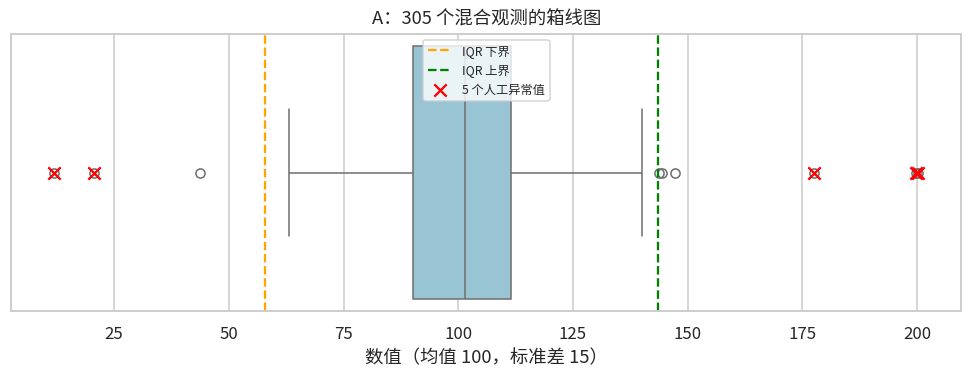

**A 题结论：**共发现 9 个异常候选，找回全部 5 个人工异常值；另有 4 个正态尾部观测被标记。这体现了 IQR 方法对极端值的筛查能力，也说明其不能自动识别数据错误。

In [3]:
# 计算四分位数和异常边界，使用严格小于或大于判定
q1, q3 = a["数值"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mask = (a["数值"] < lower) | (a["数值"] > upper)
outlier_indices = a.index[mask].tolist()
added_indices = a.index[a["来源"] == "人工异常"].tolist()
detected_added = sorted(set(outlier_indices) & set(added_indices))
normal_tail_indices = sorted(set(outlier_indices) - set(added_indices))
print(f"Q1={q1:.4f}，Q3={q3:.4f}，IQR={iqr:.4f}")
print(f"判定范围：[{lower:.4f}, {upper:.4f}]")
print("异常候选行索引（从 0 开始）：", outlier_indices)
print("检测到的人工异常索引：", detected_added)
print("另被标记的正态样本索引：", normal_tail_indices)
display(a.loc[outlier_indices])

# 绘制箱线图，并标出计算边界和人为添加值
plt.figure(figsize=(9, 3.6))
sns.boxplot(x=a["数值"], whis=1.5, color="#8fc8de")
plt.axvline(lower, color="orange", linestyle="--", label="IQR 下界")
plt.axvline(upper, color="green", linestyle="--", label="IQR 上界")
plt.scatter(added_values, np.zeros(5), color="red", marker="x", s=65, label="5 个人工异常值", zorder=5)
plt.title("A：305 个混合观测的箱线图")
plt.xlabel("数值（均值 100，标准差 15）")
plt.legend(loc="upper center", fontsize=8)
finish_plot("A_boxplot")

# 自动检查确实生成 305 个值，并找回全部 5 个人工异常值
assert len(a) == 305 and len(normal_values) == 300
assert set(added_indices).issubset(outlier_indices)
display(Markdown(f"**A 题结论：**共发现 {len(outlier_indices)} 个异常候选，找回全部 {len(detected_added)} 个人工异常值；另有 {len(normal_tail_indices)} 个正态尾部观测被标记。这体现了 IQR 方法对极端值的筛查能力，也说明其不能自动识别数据错误。"))

# B. 数据分析题：真实公开数据集探索
## B1. 查看形状、基本信息与数据含义
选择 Palmer Penguins，不使用随机生成的数据充当真实资料。`shape` 给出行数、列数；`head` 展示前几行；`info` 查看类型、非空数量与内存占用。`bill_length_mm`、`bill_depth_mm` 是喙长和喙深（毫米），`flipper_length_mm` 是鳍长（毫米），`body_mass_g` 是体重（克）。`year` 是采集年份，不当作身体测量变量；`species`、`island`、`sex` 是类别变量。

In [4]:
# 读取真实 CSV，保存一份原始数据，后续处理不覆盖源文件
penguins_raw = pd.read_csv(DATA / "penguins.csv")
print("原始形状（行，列）：", penguins_raw.shape)
display(penguins_raw.head())
penguins_raw.info()
print("完全重复行数：", penguins_raw.duplicated().sum())

原始形状（行，列）： (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB
完全重复行数： 0


## B2. 检查并处理缺失值
`isna().sum()` 按列计数，`isna().mean()` 给出比例。保留 `penguins_raw` 以审计原始缺失情况。对本题身体测量分析，删除任一身体测量缺失的观测；这是完整案例分析，可能产生选择偏差，因此报告保留数量。性别缺失填为“未知”，保留缺失含义，不猜测雄雌。这样不引入虚构的身体测量，也不把平均数填补后的数值用于相关分析。

本题以形态分析为主，描述统计、相关和物种帕累托图均使用同一份清理后的数据；帕累托图的分母明确是清理后样本数。

In [5]:
# 统计原始缺失数量与百分比
missing_b = pd.DataFrame({"缺失数": penguins_raw.isna().sum(),
                          "缺失比例(%)": penguins_raw.isna().mean() * 100})
display(missing_b.round(2))

# 仅删除 4 个身体测量中存在缺失的记录，性别缺失作为独立类别保留
measure_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins = penguins_raw.dropna(subset=measure_cols).copy()
penguins["sex"] = penguins["sex"].fillna("未知")
print(f"删除 {len(penguins_raw)-len(penguins)} 行，保留 {len(penguins)} 行")
display(penguins.isna().sum().rename("处理后缺失数").to_frame())
assert not penguins[measure_cols + ["sex"]].isna().any().any()

,缺失数,缺失比例(%)
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


删除 2 行，保留 342 行


,处理后缺失数
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0
year,0


## B3. 用 IQR 检测异常值
分别在 4 个测量列上计算边界，并保存候选行索引。只标记、不自动删除：不同物种的自然差异也可能使总体 IQR 判断失真，应回查测量单位、物种内分布及原始记录。下面的箱线图可直观看到中位数、四分位数与尾部点；每个变量单独一个子图，避免不同单位共用纵轴。

,变量,下界,上界,异常候选数,行索引
0,bill_length_mm,25.31,62.41,0,[]
1,bill_depth_mm,10.95,23.35,0,[]
2,flipper_length_mm,155.50,247.50,0,[]
3,body_mass_g,1750.00,6550.00,0,[]


至少一项测量异常的记录数： 0


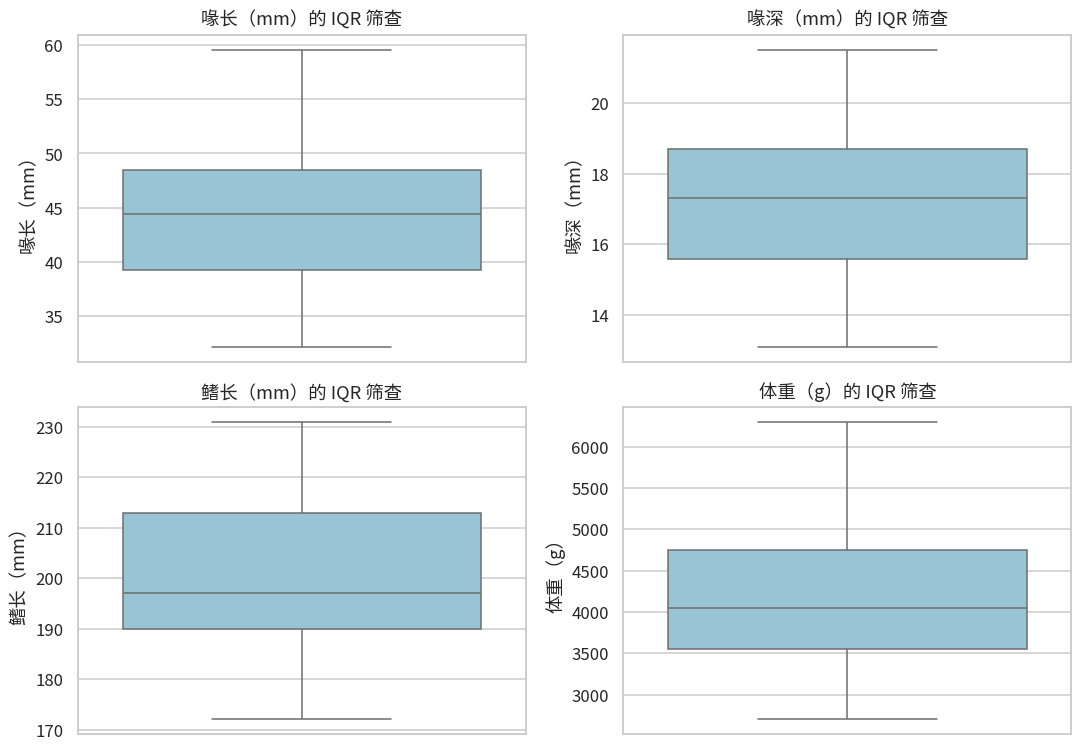

In [6]:
# 逐列计算 IQR，保存异常计数、边界和对应原始行索引
iqr_rows = []
outlier_mask_b = pd.DataFrame(False, index=penguins.index, columns=measure_cols)
for col in measure_cols:
    q1_b, q3_b = penguins[col].quantile([0.25, 0.75])
    iqr_b = q3_b - q1_b
    lo_b, hi_b = q1_b - 1.5 * iqr_b, q3_b + 1.5 * iqr_b
    flag = (penguins[col] < lo_b) | (penguins[col] > hi_b)
    outlier_mask_b[col] = flag
    iqr_rows.append({"变量": col, "下界": lo_b, "上界": hi_b,
                     "异常候选数": int(flag.sum()), "行索引": penguins.index[flag].tolist()})
iqr_table_b = pd.DataFrame(iqr_rows)
display(iqr_table_b.round(2))
print("至少一项测量异常的记录数：", outlier_mask_b.any(axis=1).sum())

# 将各变量分别画图，各自使用其原始计量单位
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
labels_b = ["喙长（mm）", "喙深（mm）", "鳍长（mm）", "体重（g）"]
for ax, col, label in zip(axes.flat, measure_cols, labels_b):
    sns.boxplot(y=penguins[col], whis=1.5, ax=ax, color="#8fc8de")
    ax.set_ylabel(label)
    ax.set_title(label + "的 IQR 筛查")
finish_plot("B_iqr")

## B4. 描述统计与相关系数热力图
`describe()` 输出样本数、均值、样本标准差（分母 n−1）、最小值、四分位数和最大值；额外输出偏度便于识别不对称。`corr(method="pearson")` 衡量线性关系，范围为 −1 到 1。把热力图固定在此范围，可防止颜色比例误导。

不对类别编码求 Pearson 相关，不把年份当作形态测量。总体相关可能受物种构成影响，所以另输出各物种的“鳍长—体重”相关作为对照。相关关系不能证明因果关系。

,count,mean,std,min,25%,50%,75%,max,skew
bill_length_mm,342.0,43.922,5.460,32.1,39.225,44.45,48.5,59.6,0.053
bill_depth_mm,342.0,17.151,1.975,13.1,15.600,17.30,18.7,21.5,-0.143
flipper_length_mm,342.0,200.915,14.062,172.0,190.000,197.00,213.0,231.0,0.346
body_mass_g,342.0,4201.754,801.955,2700.0,3550.000,4050.00,4750.0,6300.0,0.470


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000


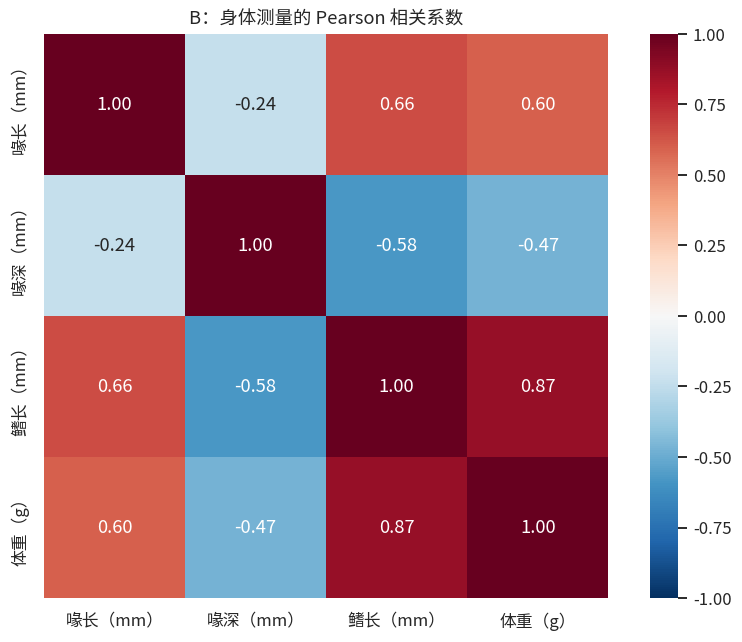

,物种,样本数,鳍长与体重相关
0,Adelie,151,0.468
1,Chinstrap,68,0.642
2,Gentoo,123,0.703


In [7]:
# 描述测量列的集中趋势、离散程度和偏度
desc_b = penguins[measure_cols].describe().T
desc_b["skew"] = penguins[measure_cols].skew()
display(desc_b.round(3))

# 只对数值型身体测量求 Pearson 相关
corr_b = penguins[measure_cols].corr(method="pearson")
display(corr_b.round(3))
plt.figure(figsize=(8, 6))
sns.heatmap(corr_b, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, xticklabels=labels_b, yticklabels=labels_b)
plt.title("B：身体测量的 Pearson 相关系数")
finish_plot("B_correlation")

# 分物种检查鳍长与体重的相关，提醒总体相关存在群组混合效应
within_species = []
for species, group in penguins.groupby("species"):
    within_species.append({"物种": species, "样本数": len(group),
                           "鳍长与体重相关": group["flipper_length_mm"].corr(group["body_mass_g"])})
display(pd.DataFrame(within_species).round(3))

## B5. 物种样本量帕累托图
帕累托图是“按数量降序排列的柱状图＋累计百分比折线图”。不是普通的无序柱状图。这里按物种统计样本量，以清理后样本为分母。80% 虚线只是参考线，不预设数据一定符合“二八定律”；样本量也不是生态总体种群数量。

,样本数,占比(%),累计占比(%)
species,,,
Adelie,151,44.15,44.15
Gentoo,123,35.96,80.12
Chinstrap,68,19.88,100.00


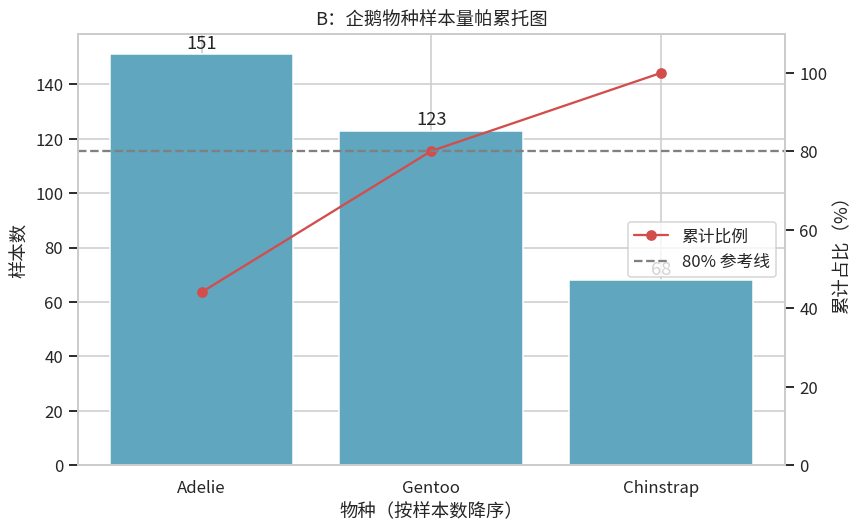

In [8]:
# 先按样本数量降序排序，再计算累计百分比
counts_b = penguins["species"].value_counts().sort_values(ascending=False)
cum_pct_b = counts_b.cumsum() / counts_b.sum() * 100
pareto_b = pd.DataFrame({"样本数": counts_b, "占比(%)": counts_b / counts_b.sum() * 100,
                         "累计占比(%)": cum_pct_b})
display(pareto_b.round(2))

# 双纵轴分别表示人数和累计百分比，两种量纲不可混用
fig, ax1 = plt.subplots(figsize=(8, 5))
x_b = np.arange(len(counts_b))
ax1.bar(x_b, counts_b.values, color="#5fa6be")
ax1.set_xticks(x_b, counts_b.index)
ax1.set_xlabel("物种（按样本数降序）")
ax1.set_ylabel("样本数")
for x, value in zip(x_b, counts_b.values):
    ax1.text(x, value + 2, str(value), ha="center")
ax2 = ax1.twinx()
ax2.plot(x_b, cum_pct_b.values, color="#d34d4d", marker="o", label="累计比例")
ax2.axhline(80, color="gray", linestyle="--", label="80% 参考线")
ax2.set_ylim(0, 110)
ax2.set_ylabel("累计占比（%）")
ax2.grid(False)
ax2.legend(loc="center right")
plt.title("B：企鹅物种样本量帕累托图")
finish_plot("B_pareto")
assert np.isclose(cum_pct_b.iloc[-1], 100)

## B6. 约 200 字分析结论
下面的结论用已计算的对象填入结果，避免手写统计量与数据不一致。结论约 200 个中文字符（含数字与标点），交代数据规模、缺失处理、异常筛查、相关和帕累托图含义。

In [9]:
# 根据真实输出生成结论，不预先猜测结果
b_conclusion = (
    f"本次分析使用{len(penguins_raw)}条真实企鹅记录，删除身体测量缺失的{len(penguins_raw)-len(penguins)}条，保留{len(penguins)}条；性别缺失标记为未知。"
    f"IQR法共标记{int(outlier_mask_b.any(axis=1).sum())}条异常候选，但这不能证明数据错误。"
    f"平均体重为{penguins['body_mass_g'].mean():.1f}克，鳍长与体重的相关系数为{corr_b.loc['flipper_length_mm','body_mass_g']:.3f}，呈正相关。"
    f"帕累托图显示{counts_b.index[0]}样本最多，前两类占{cum_pct_b.iloc[1]:.1f}%。"
    "物种构成会影响总体相关，样本占比不等于野外种群占比；缺失删除可能造成偏差，结果不宜直接推广为总体规律或因果结论。"
)
print("结论字符数（含数字和标点）：", len(b_conclusion))
display(Markdown(b_conclusion))

结论字符数（含数字和标点）： 189


本次分析使用344条真实企鹅记录，删除身体测量缺失的2条，保留342条；性别缺失标记为未知。IQR法共标记0条异常候选，但这不能证明数据错误。平均体重为4201.8克，鳍长与体重的相关系数为0.871，呈正相关。帕累托图显示Adelie样本最多，前两类占80.1%。物种构成会影响总体相关，样本占比不等于野外种群占比；缺失删除可能造成偏差，结果不宜直接推广为总体规律或因果结论。

# C. 挑战题：Kaggle Titanic 初体验（仅 EDA）
## C1. 读取训练集与确定分析口径
`Survived` 为 0（未生存）或 1（生存）；因此其分组均值正好等于生存率。`Pclass` 为 1、2、3 等舱，数值越小舱位等级越高。`Cabin` 是具体舱号，与 `Pclass` 不是同一个字段。`Fare` 为数据集记录的票价，常按英镑解读；票价可能包含共同购票等因素，不等于统一口径的人均舱位价格。

不进行模型训练、标签预测或准确率评价。年龄分析仅使用已知年龄，不用填补值虚构年龄分布；缺失年龄者另列生存率。舱号缺失保留，另外创建缺失指示列。

In [10]:
# 读取包含生存标签的 Kaggle 训练集镜像
titanic = pd.read_csv(DATA / "train.csv")
print("数据形状（行，列）：", titanic.shape)
display(titanic.head())
titanic.info()

# 检查训练集规模、标签、身份字段与舱位，防止读成 test.csv 或其他版本
expected_cols = ["PassengerId", "Survived", "Pclass", "Name", "Sex", "Age",
                 "SibSp", "Parch", "Ticket", "Fare", "Cabin", "Embarked"]
assert titanic.shape == (891, 12) and titanic.columns.tolist() == expected_cols
assert set(titanic["Survived"].unique()) == {0, 1}
assert titanic["PassengerId"].is_unique
assert set(titanic["Pclass"].unique()) == {1, 2, 3}
print("完全重复行数：", titanic.duplicated().sum())
print(f"总体生存人数：{titanic['Survived'].sum()}，总体生存率：{titanic['Survived'].mean():.2%}")

数据形状（行，列）： (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
完全重复行数： 0
总体生存人数：342，总体生存率：38.38%


## C2. 性别、舱位与生存率
`groupby` 按性别或舱位分组，`agg` 一次计算样本数、生存人数和生存率。分母是对应组全部人数，不能用生存人数直接比较风险。柱状图直接画已计算的比例；未画误差线，图中比例是该训练样本的观测值。

再交叉观察“性别×舱位”，可判断单因素差异是否受到群组构成影响；即使分层后有差异，也不能仅凭 EDA 断言因果。

,样本数,生存人数,生存率,生存率(%)
Sex,,,,
female,314,233,0.742,74.204
male,577,109,0.189,18.891


,样本数,生存人数,生存率,生存率(%)
Pclass,,,,
1,216,136,0.630,62.963
2,184,87,0.473,47.283
3,491,119,0.242,24.236


样本数  生存人数    生存率  生存率(%)
Pclass Sex                             
1      female   94    91  0.968  96.809
       male    122    45  0.369  36.885
2      female   76    70  0.921  92.105
       male    108    17  0.157  15.741
3      female  144    72  0.500  50.000
       male    347    47  0.135  13.545

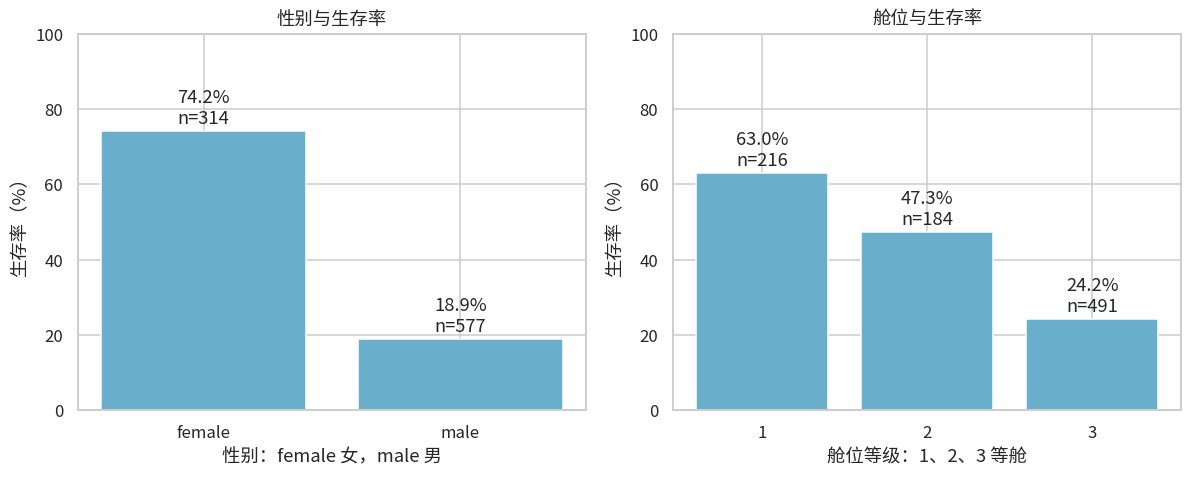

In [11]:
# 定义简单的分组汇总函数，二元变量的均值就是比例
def survival_summary(frame, by):
    result = frame.groupby(by, observed=True)["Survived"].agg(
        样本数="size", 生存人数="sum", 生存率="mean")
    result["生存率(%)"] = result["生存率"] * 100
    return result

sex_summary = survival_summary(titanic, "Sex")
class_summary = survival_summary(titanic, "Pclass")
joint_summary = survival_summary(titanic, ["Pclass", "Sex"])
display(sex_summary.round(3))
display(class_summary.round(3))
display(joint_summary.round(3))

# 使用已经汇总好的比例绘图，标签同时显示样本量
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, table, title in [(axes[0], sex_summary, "性别与生存率"),
                         (axes[1], class_summary, "舱位与生存率")]:
    ax.bar(table.index.astype(str), table["生存率(%)"], color="#69aeca")
    ax.set_ylim(0, 100)
    ax.set_ylabel("生存率（%）")
    ax.set_title(title)
    for x, (_, row) in enumerate(table.iterrows()):
        ax.text(x, row["生存率(%)"] + 2,
                f"{row['生存率(%)']:.1f}%\nn={int(row['样本数'])}", ha="center")
axes[0].set_xlabel("性别：female 女，male 男")
axes[1].set_xlabel("舱位等级：1、2、3 等舱")
finish_plot("C_sex_class_survival")

## C3. 年龄与生存率
用 `pd.cut` 将年龄分为 [0,12)、[12,18)、[18,35)、[35,60)、[60,∞) 五组；例如 12 岁进入第二组。分组是人为划定的描述口径，换边界可能影响比例。`right=False` 表示左闭右开。已知年龄者作年龄组分析；未知年龄者单独汇总，不归入任何年龄组。老年组样本较少，比例的波动可能较大。

,样本数,生存人数,生存率,生存率(%)
AgeGroup,,,,
0—11岁,68,39,0.574,57.353
12—17岁,45,22,0.489,48.889
18—34岁,366,135,0.369,36.885
35—59岁,209,87,0.416,41.627
60岁及以上,26,7,0.269,26.923


,样本数,生存率(%)
年龄缺失,177,29.379


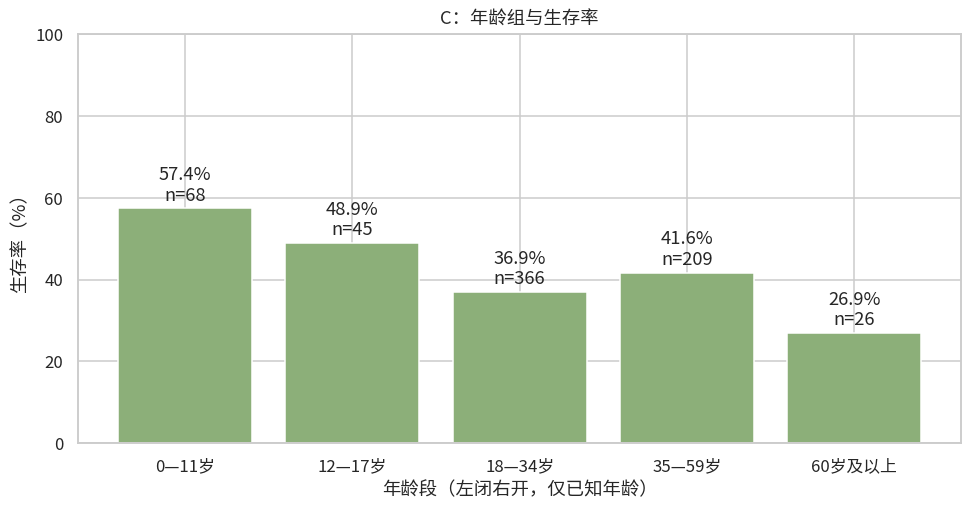

In [12]:
# 在副本上创建年龄分组，避免改变原始读取对象
titanic_eda = titanic.copy()
age_labels = ["0—11岁", "12—17岁", "18—34岁", "35—59岁", "60岁及以上"]
titanic_eda["AgeGroup"] = pd.cut(titanic_eda["Age"], bins=[0, 12, 18, 35, 60, np.inf],
                                  labels=age_labels, right=False)
age_known = titanic_eda.dropna(subset=["Age"])
age_summary = survival_summary(age_known, "AgeGroup")
display(age_summary.round(3))
age_missing_summary = pd.DataFrame({"样本数": [titanic["Age"].isna().sum()],
    "生存率(%)": [titanic.loc[titanic["Age"].isna(), "Survived"].mean() * 100]}, index=["年龄缺失"])
display(age_missing_summary.round(3))

# 绘制年龄段的生存率，保留每组分母以方便解释结果
plt.figure(figsize=(9, 4.8))
plt.bar(age_summary.index.astype(str), age_summary["生存率(%)"], color="#8caf79")
plt.ylim(0, 100)
plt.ylabel("生存率（%）")
plt.xlabel("年龄段（左闭右开，仅已知年龄）")
plt.title("C：年龄组与生存率")
for x, (_, row) in enumerate(age_summary.iterrows()):
    plt.text(x, row["生存率(%)"] + 2, f"{row['生存率(%)']:.1f}%\nn={int(row['样本数'])}", ha="center")
finish_plot("C_age_survival")
assert int(age_summary["样本数"].sum()) == int(titanic["Age"].notna().sum())

## C4. 缺失值分布模式：年龄、舱号及其他字段
先统计全部字段缺失数量和比例，再画缺失矩阵。矩阵横轴为变量，纵轴为按舱位排序的乘客；红色表示缺失，不是变量数值。排序后可直观看到缺失是否集中。

将 `Age` 和 `Cabin` 的缺失转为布尔指示变量，分组均值就是缺失率。按舱位、性别、生存标签分别汇总，并用交叉表观察年龄缺失与舱号缺失是否同时出现。不能仅凭这些表证明数据满足“完全随机缺失”或“非随机缺失”的严格机制。

,缺失数,缺失比例(%)
PassengerId,0,0.000
Survived,0,0.000
Pclass,0,0.000
Name,0,0.000
Sex,0,0.000
Age,177,19.865
SibSp,0,0.000
Parch,0,0.000
Ticket,0,0.000
Fare,0,0.000


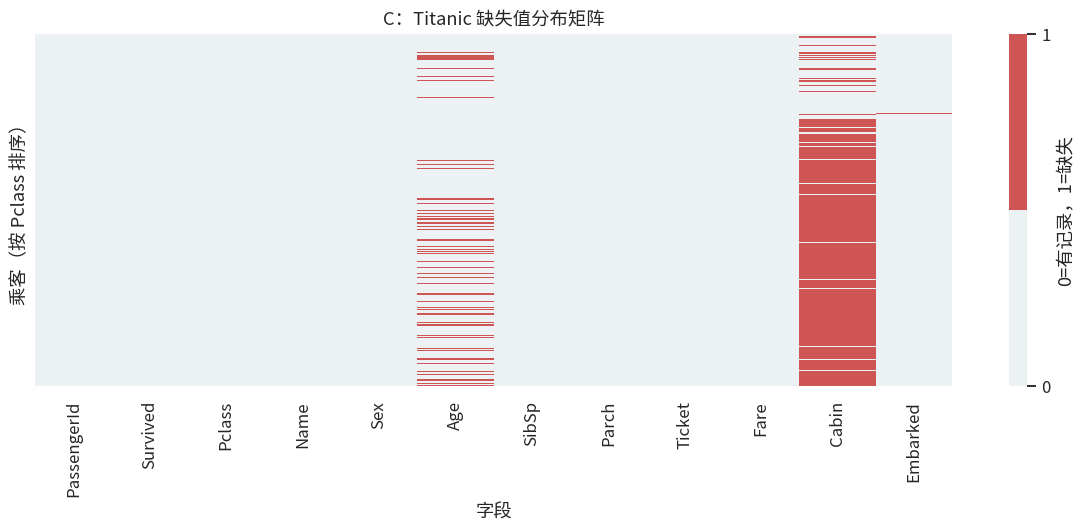

各舱位缺失率（%）：


,AgeMissing,CabinMissing
Pclass,,
1,13.89,18.52
2,5.98,91.30
3,27.70,97.56


各性别缺失率（%）：


,AgeMissing,CabinMissing
Sex,,
female,16.88,69.11
male,21.49,81.46


各生存标签缺失率（%）：


,AgeMissing,CabinMissing
Survived,,
0,22.77,87.61
1,15.20,60.23


年龄与舱号缺失的联合分布（False=有记录，True=缺失）：


CabinMissing,False,True,All
AgeMissing,,,
False,185,529,714
True,19,158,177
All,204,687,891


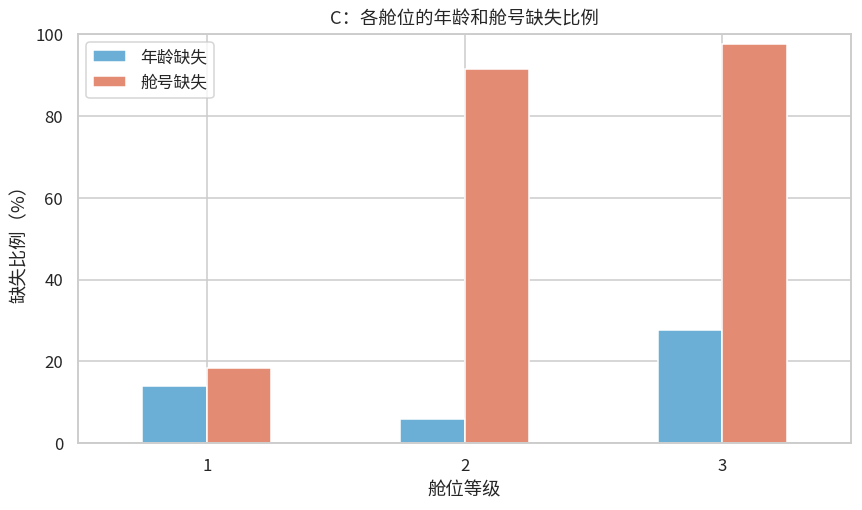

In [13]:
# 统计每一列的缺失情况，缺失比例的分母均为 891 名乘客
missing_c = pd.DataFrame({"缺失数": titanic.isna().sum(),
                          "缺失比例(%)": titanic.isna().mean() * 100})
display(missing_c.round(3))

# 按舱位排序显示缺失矩阵，排序不会更改原始数据
ordered_missing = titanic.sort_values("Pclass", kind="stable").isna().astype(int)
plt.figure(figsize=(11, 5))
sns.heatmap(ordered_missing, cmap=["#ecf1f4", "#cf5555"], vmin=0, vmax=1,
            yticklabels=False, cbar_kws={"ticks": [0, 1], "label": "0=有记录，1=缺失"})
plt.xlabel("字段")
plt.ylabel("乘客（按 Pclass 排序）")
plt.title("C：Titanic 缺失值分布矩阵")
finish_plot("C_missing_matrix")

# 缺失指示变量只表示是否缺失，不填补年龄或具体舱号
titanic_eda["AgeMissing"] = titanic_eda["Age"].isna()
titanic_eda["CabinMissing"] = titanic_eda["Cabin"].isna()
missing_by_class = titanic_eda.groupby("Pclass")[["AgeMissing", "CabinMissing"]].mean() * 100
missing_by_sex = titanic_eda.groupby("Sex")[["AgeMissing", "CabinMissing"]].mean() * 100
missing_by_survival = titanic_eda.groupby("Survived")[["AgeMissing", "CabinMissing"]].mean() * 100
print("各舱位缺失率（%）：")
display(missing_by_class.round(2))
print("各性别缺失率（%）：")
display(missing_by_sex.round(2))
print("各生存标签缺失率（%）：")
display(missing_by_survival.round(2))
print("年龄与舱号缺失的联合分布（False=有记录，True=缺失）：")
display(pd.crosstab(titanic_eda["AgeMissing"], titanic_eda["CabinMissing"], margins=True))

# 缺失比例的柱形图用于直接比较舱位差异
missing_by_class.rename(columns={"AgeMissing": "年龄缺失", "CabinMissing": "舱号缺失"}).plot(
    kind="bar", figsize=(8, 4.8), rot=0, color=["#6baed6", "#e38b73"])
plt.ylim(0, 100)
plt.xlabel("舱位等级")
plt.ylabel("缺失比例（%）")
plt.title("C：各舱位的年龄和舱号缺失比例")
finish_plot("C_missing_by_class")

## C5. 不同舱位的票价箱线图
原始票价分布右偏，高价点会拉长纵轴。左图保留原始票价便于识别真实金额；右图画 `log1p(Fare)=ln(1+Fare)`，使零票价也能保留。注意右图箱线图边界在变换尺度上计算，不能与原始金额的 IQR 候选逐点等同。

按舱位计算票价描述统计和原始尺度 IQR 候选数，不自动删除高票价。零票价也只标记以供回查，不未经核实当成缺失。

,count,mean,std,min,25%,50%,75%,max
Pclass,,,,,,,,
1,216.0,84.155,78.380,0.0,30.924,60.287,93.5,512.329
2,184.0,20.662,13.417,0.0,13.000,14.250,26.0,73.500
3,491.0,13.676,11.778,0.0,7.750,8.050,15.5,69.550


,舱位,下界,上界,票价异常候选数,零票价人数
0,1,-62.940,187.364,20,5
1,2,-6.500,45.500,7,6
2,3,-3.875,27.125,52,4


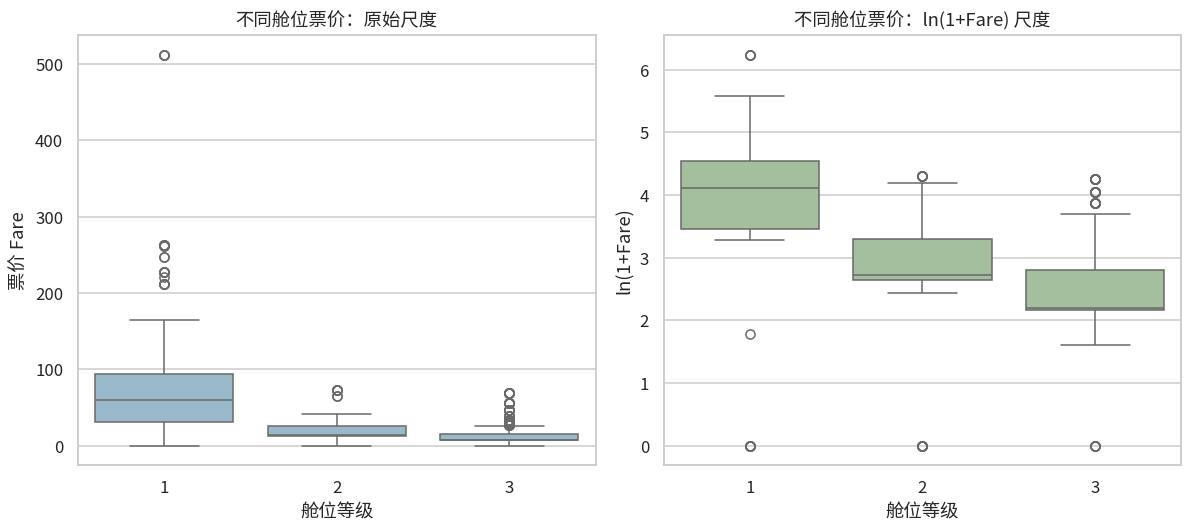

In [14]:
# 先核查票价范围，再进行对数变换，log1p 可以处理 0
assert (titanic["Fare"] >= 0).all()
fare_summary = titanic.groupby("Pclass")["Fare"].describe()
fare_flags = []
for pclass, group in titanic.groupby("Pclass"):
    q1_f, q3_f = group["Fare"].quantile([0.25, 0.75])
    iqr_f = q3_f - q1_f
    lo_f, hi_f = q1_f - 1.5 * iqr_f, q3_f + 1.5 * iqr_f
    flagged = (group["Fare"] < lo_f) | (group["Fare"] > hi_f)
    fare_flags.append({"舱位": pclass, "下界": lo_f, "上界": hi_f,
                       "票价异常候选数": int(flagged.sum()), "零票价人数": int((group["Fare"] == 0).sum())})
display(fare_summary.round(3))
display(pd.DataFrame(fare_flags).round(3))
titanic_eda["LogFare"] = np.log1p(titanic_eda["Fare"])

# 左右两图分别使用原始金额和变换值，标题明确注明尺度
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sns.boxplot(data=titanic_eda, x="Pclass", y="Fare", order=[1, 2, 3], ax=axes[0], color="#91bad1")
sns.boxplot(data=titanic_eda, x="Pclass", y="LogFare", order=[1, 2, 3], ax=axes[1], color="#a1c597")
axes[0].set_title("不同舱位票价：原始尺度")
axes[0].set_ylabel("票价 Fare")
axes[1].set_title("不同舱位票价：ln(1+Fare) 尺度")
axes[1].set_ylabel("ln(1+Fare)")
for ax in axes:
    ax.set_xlabel("舱位等级")
finish_plot("C_fare_boxplot")

## C6. 数据分析报告：从数据看到的规律
下面报告的所有数字直接来自本次运行的汇总表。描述性结论只针对 Kaggle 训练样本。年龄是非随机记录缺失的可能性需要重视；只分析已知年龄者可能改变样本构成。分层统计有助于观察混杂，但不能替代严谨的因果设计。

In [15]:
# 从当前数据生成报告，以确保文字与图表使用同一口径
c_report = f"""
### 1. 数据与方法
使用 Kaggle Titanic 训练集公开镜像的 {len(titanic)} 名乘客、{titanic.shape[1]} 个字段。生存标签均有记录，共 {int(titanic['Survived'].sum())} 人生存，总体生存率 {titanic['Survived'].mean():.2%}。采用分组统计、缺失矩阵及箱线图，不建立预测模型。

### 2. 性别与舱位
女性 {int(sex_summary.loc['female','样本数'])} 人，生存率 {sex_summary.loc['female','生存率']:.2%}；男性 {int(sex_summary.loc['male','样本数'])} 人，生存率 {sex_summary.loc['male','生存率']:.2%}。一、二、三等舱生存率分别为 {class_summary.loc[1,'生存率']:.2%}、{class_summary.loc[2,'生存率']:.2%}、{class_summary.loc[3,'生存率']:.2%}，此样本中一等舱最高。性别×舱位表中各舱位的女性生存率均高于同舱男性，但这仍是关联描述。

### 3. 年龄
已知年龄 {len(age_known)} 人。0—11 岁组 {int(age_summary.iloc[0]['样本数'])} 人，生存率 {age_summary.iloc[0]['生存率']:.2%}；60 岁及以上组 {int(age_summary.iloc[-1]['样本数'])} 人，生存率 {age_summary.iloc[-1]['生存率']:.2%}。各年龄组生存率并非严格随年龄单调变化，不能概括为每增加一岁都会降低生存率；年龄分组边界和小样本都会影响结果。年龄缺失者生存率为 {age_missing_summary.iloc[0]['生存率(%)']:.2f}%，与完整年龄样本的口径应区分。

### 4. 缺失模式与处理
年龄缺失 {int(missing_c.loc['Age','缺失数'])} 条（{missing_c.loc['Age','缺失比例(%)']:.2f}%），舱号缺失 {int(missing_c.loc['Cabin','缺失数'])} 条（{missing_c.loc['Cabin','缺失比例(%)']:.2f}%），登船港缺失 {int(missing_c.loc['Embarked','缺失数'])} 条。三等舱舱号缺失率 {missing_by_class.loc[3,'CabinMissing']:.2f}%，一等舱为 {missing_by_class.loc[1,'CabinMissing']:.2f}%，缺失明显与舱位有关，不宜直接认为完全随机。本文保留缺失并建立标记，只在年龄分组时排除未知年龄；没有用平均年龄填补，也没有猜测舱号。登船港不参与本次重点分析，保留缺失。

### 5. 票价及综合结论
一、二、三等舱票价中位数分别为 {fare_summary.loc[1,'50%']:.3f}、{fare_summary.loc[2,'50%']:.3f}、{fare_summary.loc[3,'50%']:.3f}。原始箱线图呈现高价尾部，变换图更便于比较中间区域；高价候选和零票价需要结合购票背景核查，不自动删除。性别、舱位和年龄均呈现样本内生存差异，但相互关联、选择偏差、历史救援安排等因素使本报告无法据此确定因果关系，亦不能把训练样本当作所有乘客的无偏普查。
"""
display(Markdown(c_report))

# 检查报告中的比较结论与真实分层表保持一致
assert (joint_summary.xs("female", level="Sex")["生存率"] >
        joint_summary.xs("male", level="Sex")["生存率"]).all()


### 1. 数据与方法
使用 Kaggle Titanic 训练集公开镜像的 891 名乘客、12 个字段。生存标签均有记录，共 342 人生存，总体生存率 38.38%。采用分组统计、缺失矩阵及箱线图，不建立预测模型。

### 2. 性别与舱位
女性 314 人，生存率 74.20%；男性 577 人，生存率 18.89%。一、二、三等舱生存率分别为 62.96%、47.28%、24.24%，此样本中一等舱最高。性别×舱位表中各舱位的女性生存率均高于同舱男性，但这仍是关联描述。

### 3. 年龄
已知年龄 714 人。0—11 岁组 68 人，生存率 57.35%；60 岁及以上组 26 人，生存率 26.92%。各年龄组生存率并非严格随年龄单调变化，不能概括为每增加一岁都会降低生存率；年龄分组边界和小样本都会影响结果。年龄缺失者生存率为 29.38%，与完整年龄样本的口径应区分。

### 4. 缺失模式与处理
年龄缺失 177 条（19.87%），舱号缺失 687 条（77.10%），登船港缺失 2 条。三等舱舱号缺失率 97.56%，一等舱为 18.52%，缺失明显与舱位有关，不宜直接认为完全随机。本文保留缺失并建立标记，只在年龄分组时排除未知年龄；没有用平均年龄填补，也没有猜测舱号。登船港不参与本次重点分析，保留缺失。

### 5. 票价及综合结论
一、二、三等舱票价中位数分别为 60.287、14.250、8.050。原始箱线图呈现高价尾部，变换图更便于比较中间区域；高价候选和零票价需要结合购票背景核查，不自动删除。性别、舱位和年龄均呈现样本内生存差异，但相互关联、选择偏差、历史救援安排等因素使本报告无法据此确定因果关系，亦不能把训练样本当作所有乘客的无偏普查。


# D. 思考题：电商数据侦探
假设字段为用户 ID、下单时间、商品类别、金额、是否退货。以下是**可能遇到的问题及方案**，不是声称已分析了某份电商文件。处理顺序建议：先核查结构、业务口径与主键，再查缺失和类型，最后做数值与跨字段逻辑检查。保留原始表、清理日志和隔离区，不能为了“干净”而丢弃真实交易。

| 序号 | 问题与具体例子 | 检查方法 | 处理方案 |
| --- | --- | --- | --- |
| 1 | 用户 ID 缺失、前导零丢失，如 00123 被读成 123 | 查看空值、长度和格式，与用户主表核对 | 以字符串读取；能从订单系统找回则补回，否则隔离并标为未知用户；不随机造 ID，也不盲目补前导零 |
| 2 | 重复记录或重复上报 | 找完全相同行；有订单 ID 时按主键和事件时间检查 | 核实重复上报后只留一条并记录日志；现有五字段不足以区分两笔真实同额订单，应申请订单 ID，不能仅凭五字段一致就删单 |
| 3 | 时间格式混杂、无效或未来时间，如 2024-13-01 | 用 pd.to_datetime(errors='coerce') 标记解析失败，检查范围 | 统一日期格式与时区；回查原始日志修正，无法修正则保留 NaT 并标记；不能把失败值替换成当前时间 |
| 4 | 商品类别拼写不一、空格或层级混用，如 手机、手机类、 手机 | 统计唯一值和频数，与商品分类字典比对 | 去首尾空格，按经审核的字典映射标准分类；未知类别单列，保留原字段与映射版本，不把所有未知强制归为主流类 |
| 5 | 金额为字符串、币种或单位混杂，如 ¥1,299、129900 分 | 核查类型、货币符号、千位分隔符、币种与金额单位 | 解析为数值并统一货币和单位；汇率使用交易日口径；保存原金额和币种，缺少币种依据时隔离，不能擅自按同一货币求和 |
| 6 | 金额缺失、负值、零值或极端高值 | 数值转换后检查缺失、范围，按类别做 IQR 筛查 | 查是否退款、赠品、优惠或录入错误；真值保留并标记，证实错误才更正；未知金额不填 0，高价不一律删除 |
| 7 | 退货标签含 是/否、Y/N、0/1 或空值 | 列出不同标签并核实业务定义与状态含义 | 明确映射到统一的 0/1；未完成或未知状态单独保留为缺失，不能默认未退货；保留映射规则 |
| 8 | 跨字段与状态矛盾，如退货记录时间早于购买，负金额却标注普通销售 | 与订单状态、退款流水、退货时间进行联合校验 | 当前五字段不足以完整验证，补充订单 ID、退货时间和退款金额；按业务规则区分购买额与退款额，隔离矛盾记录交人工核查 |
| 9 | 数据截取导致退货率偏低：新订单尚未过退货窗口 | 按订单日期看可观察时长，核对观察截止日 | 定义统一的退货观察窗口；只比较窗口已结束的订单，或单列未成熟订单，报告分母及截止日 |

**原则说明：**先区分真实极端交易与错误记录；缺失、异常和重复的处理均需业务证据。分析退货率时明确订单口径、有效分母与观察窗口。这里不给出虚构的电商统计结果。

## 最后检查与学习小结
A 学习随机生成、四分位数和布尔筛选；B 学习形状、缺失、异常、统计、相关和帕累托图；C 学习二元变量均值、分组分析及缺失偏差；D 学习业务口径与清理审计。没有进行预测建模。

以下检查仅确认文件生成及关键分析对象一致，分析结果还需结合统计假设和业务背景解释。Word 报告根据已运行 Notebook 的文字、代码、表格和图表生成；不得将无数据支持的表述当作结论。

In [16]:
# 对全部图像文件做实际读取检查，不只判断文件名存在
expected_figures = ["A_boxplot", "B_iqr", "B_correlation", "B_pareto",
                    "C_sex_class_survival", "C_age_survival", "C_missing_matrix",
                    "C_missing_by_class", "C_fare_boxplot"]
for name in expected_figures:
    image = plt.imread(FIG / f"{name}.png")
    assert image.ndim == 3 and image.shape[0] > 100 and image.shape[1] > 100
print(f"已验证 {len(expected_figures)} 张图均可读取，尺寸有效。")
print("A：全部 5 个人工异常已检出；B：清理、统计、相关、帕累托完成；C：仅 EDA；D：9 类问题与方案。")

已验证 9 张图均可读取，尺寸有效。
A：全部 5 个人工异常已检出；B：清理、统计、相关、帕累托完成；C：仅 EDA；D：9 类问题与方案。
